# WQF7009 Assignment 1: Using SHAP for Stroke Prediction Model
## Part 2: Logistic Regression

Author: Gan Yee Jing (25102061)

Creation Date: 2026-11-02

Trains a logistic regression on the cleaned train/test files exported from `01_eda.ipynb`, then explains it with SHAP: the explainer (Task 2), local explanations with force plots (Task 3) and the global explanation with a summary plot (Task 4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, balanced_accuracy_score, RocCurveDisplay)
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

C:\Users\hp\Downloads\Master\02_Sem1\WQF7009 - Explainable Artificial Intelligence (XAI)\WQF7009---Assignment-1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### a) Load data

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

target = "stroke"
X_train, y_train = train.drop(columns=["id", target]), train[target]
X_test, y_test = test.drop(columns=["id", target]), test[target]

print(f"Train: {X_train.shape}, stroke rate {y_train.mean():.2%}")
print(f"Test:  {X_test.shape}, stroke rate {y_test.mean():.2%}")
X_train.head()

Train: (4087, 9), stroke rate 4.87%
Test:  (1022, 9), stroke rate 4.89%


,gender,age,hypertension,heart_disease,Residence_type,avg_glucose_level,bmi,smoking_status,bmi_missing
0,Female,48.0,0,0,Urban,69.21,33.1,never smoked,0
1,Female,29.0,0,0,Urban,84.19,21.2,never smoked,0
2,Female,35.0,0,0,Rural,119.40,22.9,never smoked,0
3,Male,38.0,0,0,Rural,108.68,32.7,never smoked,0
4,Male,14.0,0,0,Urban,82.34,31.6,Unknown,0


### b) Preprocessing and model
| Feature type | Columns | Encoding |
|---|---|---|
| Numeric | `age`, `avg_glucose_level`, `bmi` | Standardised (fitted on train) |
| Categorical | `gender`, `Residence_type`, `smoking_status` | One-hot, first category dropped |
| Boolean | `hypertension`, `heart_disease`, `bmi_missing` | Unchanged |

`ever_married` and `work_type` are not used: they were dropped in `01_eda.ipynb` (section f) as age proxies.

`class_weight="balanced"` handles the class imbalance (~4.9% stroke) by giving stroke cases more weight.

In [3]:
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "Residence_type", "smoking_status"]  # ever_married and work_type dropped in 01_eda.ipynb
bin_cols = ["hypertension", "heart_disease", "bmi_missing"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
], verbose_feature_names_out=False)

model = Pipeline([
    ("preprocess", preprocess),
    ("lr", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('lr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['gender','age','hypertension',...,'bmi','smoking_status','bmi_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `ve

**Decision threshold**

The threshold is chosen from out-of-fold predictions on the training set, not from the test set.

In [4]:
oof = cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba")[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flag = oof >= t
    rows.append({"threshold": t, "recall": flag[y_train == 1].mean(), "precision": y_train[flag].mean(),
                 "flagged": flag.mean()})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,flagged
0,0.3,0.930,0.105,0.432
1,0.4,0.874,0.123,0.345
2,0.5,0.799,0.141,0.276
3,0.6,0.714,0.159,0.218
4,0.7,0.613,0.187,0.159
5,0.8,0.367,0.213,0.084


**Interpretation:** a lower threshold catches more strokes but flags many more patients; a higher one does the opposite. The default of 0.5 is kept: it detects about 80% of strokes in the training folds while flagging 28% of patients, a reasonable balance for a screening aid where a missed stroke costs more than a false alarm.

### c) Evaluation

In [5]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print(f"Threshold: 0.5 (default), positive class support: {y_test.sum()} of {len(y_test)}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.3f}")
print(f"PR AUC (average precision): {average_precision_score(y_test, y_prob):.3f} (baseline {y_test.mean():.3f})")
print(f"Confusion matrix: TN {tn}, FP {fp}, FN {fn}, TP {tp}")
print()
print(classification_report(y_test, y_pred, target_names=["No stroke", "Stroke"], digits=3))

Threshold: 0.5 (default), positive class support: 50 of 1022
Balanced accuracy: 0.777
ROC AUC: 0.835
PR AUC (average precision): 0.216 (baseline 0.049)
Confusion matrix: TN 732, FP 240, FN 10, TP 40

              precision    recall  f1-score   support

   No stroke      0.987     0.753     0.854       972
      Stroke      0.143     0.800     0.242        50

    accuracy                          0.755      1022
   macro avg      0.565     0.777     0.548      1022
weighted avg      0.945     0.755     0.824      1022



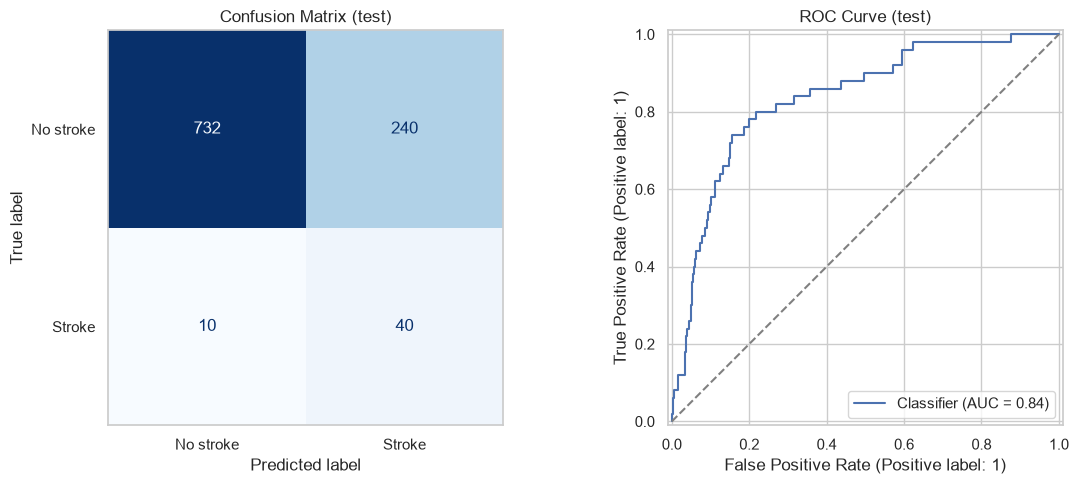

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No stroke", "Stroke"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (test)")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], ls="--", color="grey")
axes[1].set_title("ROC Curve (test)")
plt.tight_layout()
plt.show()

**Missed strokes (false negatives)**

In [7]:
missed = test[(y_test == 1) & (y_pred == 0)]
print(f"Missed strokes: {len(missed)} of {y_test.sum()}")
print(f"Age of missed strokes: median {missed['age'].median():.0f}, range {missed['age'].min():.0f} to {missed['age'].max():.0f}")
print(f"Age of detected strokes: median {test[(y_test == 1) & (y_pred == 1)]['age'].median():.0f}")
missed[['id', 'age', 'gender', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing']].assign(
    probability=y_prob[missed.index]).round(3)

Missed strokes: 10 of 50
Age of missed strokes: median 40, range 14 to 59
Age of detected strokes: median 78


,id,age,gender,hypertension,heart_disease,avg_glucose_level,bmi_missing,probability
135,31563,38.0,Female,0,0,101.45,1,0.473
165,54385,45.0,Male,0,0,64.14,0,0.143
240,39912,32.0,Female,0,0,76.13,0,0.110
253,14499,47.0,Male,0,0,86.94,0,0.261
285,57419,59.0,Male,0,0,96.16,0,0.416
521,33943,39.0,Female,0,0,83.24,0,0.128
553,49669,14.0,Female,0,0,57.93,0,0.019
686,33879,42.0,Male,0,0,83.41,0,0.127
949,47306,58.0,Male,0,0,92.62,0,0.357
978,31154,39.0,Female,0,0,97.76,0,0.207


### d) Task 2: SHAP explainer

**1. Explainer used**
- `shap.LinearExplainer`, because logistic regression is a linear model. It gives exact SHAP values.

**2. SHAP value of a feature**

$$\phi_j = \beta_j \times (x_j - \bar{x}_j)$$

- $\phi_j$: SHAP value of feature $j$, i.e. how much it pushes this patient's risk up (+) or down (−)
- $\beta_j$: model coefficient of feature $j$
- $x_j$: this patient's value of feature $j$
- $\bar{x}_j$: average value of feature $j$ in the training set 

**3. Final prediction of a patient**

$$f(x) = \text{base value} + \sum_j \phi_j$$

- base value: the model's average prediction
- $f(x)$ is in log-odds; probability of stroke $= \dfrac{1}{1 + e^{-f(x)}}$

In [8]:
# Transform the data the same way the model sees it
feature_names = model.named_steps["preprocess"].get_feature_names_out()
X_train_t = pd.DataFrame(model.named_steps["preprocess"].transform(X_train), columns=feature_names, index=X_train.index)
X_test_t = pd.DataFrame(model.named_steps["preprocess"].transform(X_test), columns=feature_names, index=X_test.index)

# Create the explainer with the full training set as base, then explain the test set
masker = shap.maskers.Independent(X_train_t, max_samples=len(X_train_t))
explainer = shap.LinearExplainer(model.named_steps["lr"], masker)
shap_values = explainer(X_test_t)

# Show numeric features in original units in the plots
X_test_display = X_test_t.copy()
X_test_display[num_cols] = X_test[num_cols].values
shap_values.data = X_test_display.round(2).values

base = explainer.expected_value
print(f"Base value: {base:.3f} log-odds (probability {1 / (1 + np.exp(-base)):.3f})")

print("Model classes:", model.classes_, "-> explained output index 1 (stroke)")
print(f"Transformed features ({len(feature_names)}):", list(feature_names))
print("Background:", X_train_t.shape, "| explained:", X_test_t.shape, "| SHAP values:", shap_values.values.shape)

Base value: -1.323 log-odds (probability 0.210)
Model classes: [0 1] -> explained output index 1 (stroke)
Transformed features (11): ['age', 'avg_glucose_level', 'bmi', 'gender_Male', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'hypertension', 'heart_disease', 'bmi_missing']
Background: (4087, 11) | explained: (1022, 11) | SHAP values: (1022, 11)


**Verification**

For an additive explanation, base value + sum of SHAP values must reproduce the model output on the explained scale (log-odds here, not probability).

In [9]:
log_odds = model.named_steps["lr"].decision_function(X_test_t)
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
residual = np.abs(reconstructed - log_odds)
print(f"Feature names match: {list(X_test_t.columns) == list(shap_values.feature_names)}")
print(f"Max reconstruction residual: {residual.max():.2e} log-odds (tolerance 1e-6): "
      f"{'pass' if residual.max() < 1e-6 else 'FAIL'}")
print(f"Probabilities match predict_proba: {np.allclose(1 / (1 + np.exp(-reconstructed)), y_prob)}")

Feature names match: True
Max reconstruction residual: 1.78e-15 log-odds (tolerance 1e-6): pass
Probabilities match predict_proba: True


C:\Users\hp\Downloads\Master\02_Sem1\WQF7009 - Explainable Artificial Intelligence (XAI)\WQF7009---Assignment-1\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


### e) Task 3: Local explanation (force plot)
Explains individual patients. One test patient is shown for each prediction outcome, picking the case where the model is most confident:

| Case | Actual | Predicted | Patient shown |
|---|---|---|---|
| True Positive (TP) | Stroke | Stroke | Highest predicted risk |
| True Negative (TN) | No stroke | No stroke | Lowest predicted risk |
| False Positive (FP) | No stroke | Stroke | Highest predicted risk (most confident false alarm) |
| False Negative (FN) | Stroke | No stroke | Lowest predicted risk (most confident miss) |

**How to read the force plot**
- The scale is log-odds. `base value` is the average prediction; `f(x)` is this patient's prediction.
- Red features push the risk up; blue features push it down. Wider arrows mean a bigger effect.
- Only features with a noticeable contribution are labelled.

**Interpretation** (starting from base value −1.32)
- **TP (id 8213, f(x) = 3.44):** a 78-year-old with missing BMI, heart disease and high glucose (219.8). Age (+2.63) and missing BMI (+1.62) push the risk far above the base value. The model correctly flags this patient.
- **TN (id 68598, f(x) = −5.15):** a 1-year-old with low glucose and BMI. Young age (−3.20) alone pulls the risk far below the base value. The model correctly rules out stroke.
- **FP (id 49894, f(x) = 4.04):** a 78-year-old with missing BMI, hypertension, heart disease and high glucose (206.5). Every major risk factor is present, so the model flags her, but she has no recorded stroke. The data contain nothing that could explain why.
- **FN (id 49669, f(x) = −3.93):** a 14-year-old who did have a stroke. Young age (−2.22) dominates and pulls the risk down, so the stroke is missed. This shows the model's main weakness: it relies heavily on age and misses strokes in young patients.

True Positive | id 8213 | actual: 1 | predicted: 1 | probability: 0.969


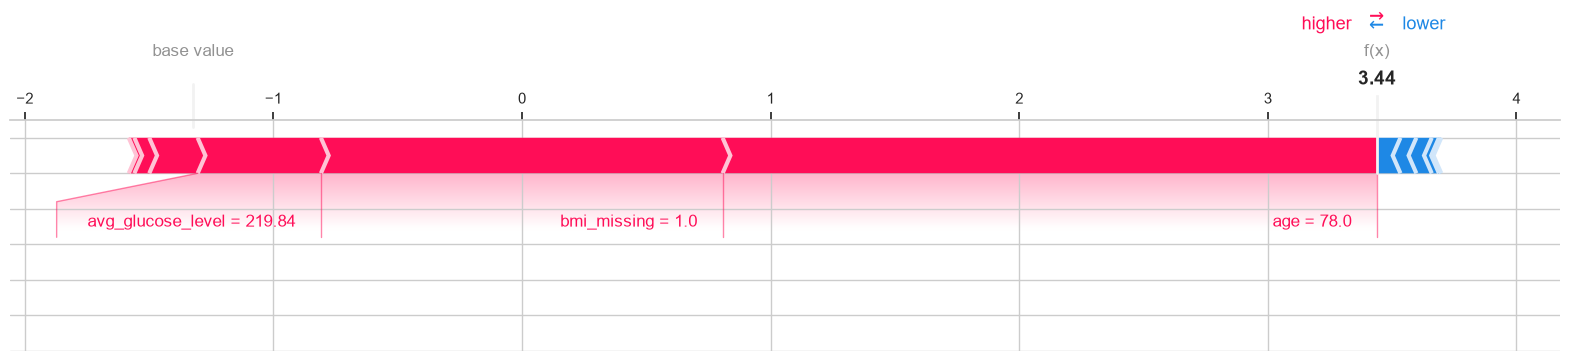

True Negative | id 68598 | actual: 0 | predicted: 0 | probability: 0.006


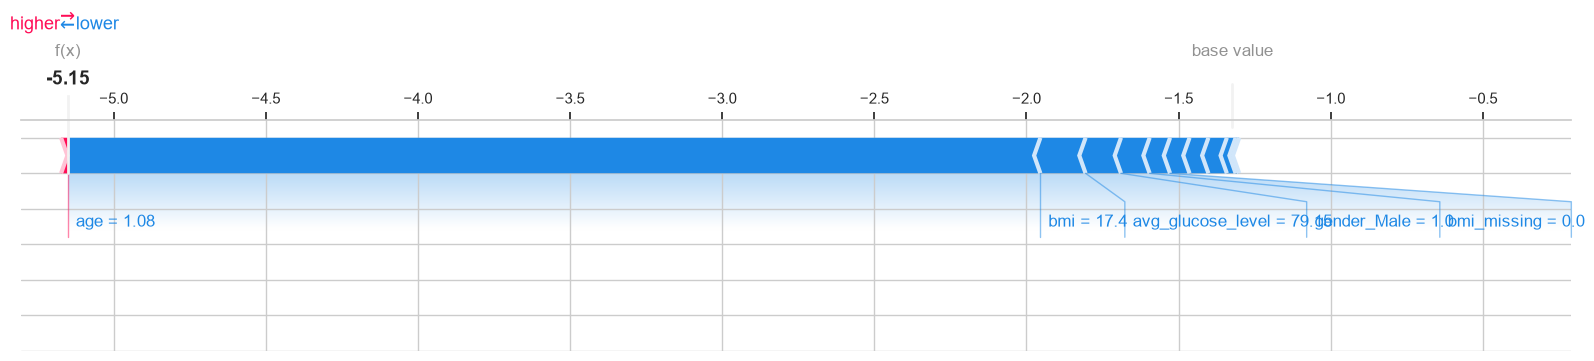

False Positive | id 49894 | actual: 0 | predicted: 1 | probability: 0.983


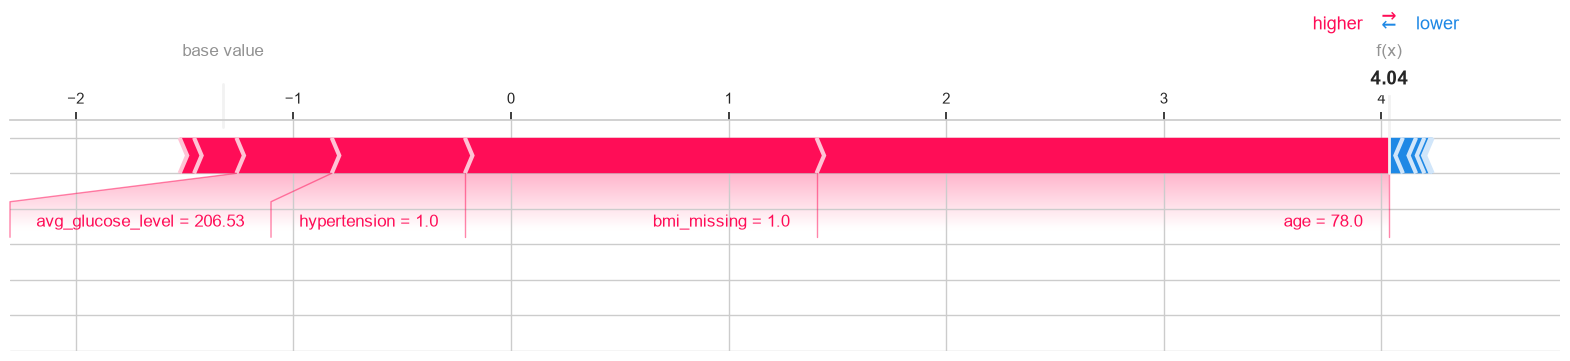

False Negative | id 49669 | actual: 1 | predicted: 0 | probability: 0.019


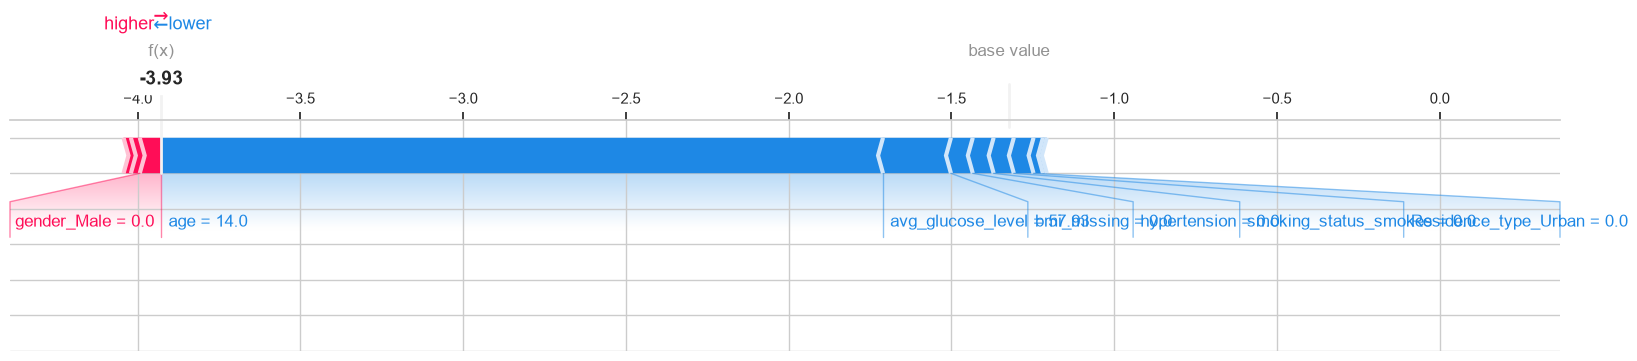

In [10]:
def plot_force(i, title):
    """Force plot for the i-th test patient."""
    print(f"{title} | id {test['id'].iloc[i]} | actual: {y_test.iloc[i]} | predicted: {y_pred[i]} | probability: {y_prob[i]:.3f}")
    shap.plots.force(shap_values[i], matplotlib=True, figsize=(20, 3), contribution_threshold=0.1)


actual, pred = y_test.values, y_pred
cases = {
    "True Positive":  (actual == 1) & (pred == 1),
    "True Negative":  (actual == 0) & (pred == 0),
    "False Positive": (actual == 0) & (pred == 1),
    "False Negative": (actual == 1) & (pred == 0),
}

for name, mask in cases.items():
    idx = np.where(mask)[0]
    # Most confident example of each case: highest risk for positive predictions, lowest for negative
    i = idx[np.argmax(y_prob[idx])] if name in ("True Positive", "False Positive") else idx[np.argmin(y_prob[idx])]
    plot_force(i, name)

**Single Prediction Analysis**

Feature contributions for this patient, largest first. The remaining features are combined into one row.

In [11]:
def contributions(sv, i, top=4):
    """Largest SHAP contributions for one patient, with the rest combined."""
    s = pd.DataFrame({"value": sv.data[i], "shap": sv.values[i]}, index=sv.feature_names)
    s = s.reindex(s["shap"].abs().sort_values(ascending=False).index)
    out = s.head(top).copy()
    out.loc["Remaining features combined"] = [np.nan, s["shap"].iloc[top:].sum()]
    out["direction"] = np.where(out["shap"] > 0, "increases", "decreases")
    return out.round(3)


tp = np.where((actual == 1) & (pred == 1))[0]
main = int(tp[np.argmax(y_prob[tp])])  # highest-risk true positive
print(f"Row {main}, id {test['id'].iloc[main]} | base {base:.3f} -> f(x) {log_odds[main]:.3f} log-odds "
      f"(probability {y_prob[main]:.3f}), check: {base + shap_values.values[main].sum():.3f}")
contributions(shap_values, main)

Row 207, id 8213 | base -1.323 -> f(x) 3.439 log-odds (probability 0.969), check: 3.439


,value,shap,direction
age,78.00,2.632,increases
bmi_missing,1.00,1.616,increases
avg_glucose_level,219.84,0.496,increases
heart_disease,1.00,0.195,increases
Remaining features combined,NaN,-0.176,decreases


**Interpretation:** starting from the base value of −1.323, the output moves to 3.439 log-odds (probability 0.969). Age (+2.63), missing BMI (+1.62), glucose (+0.50) and heart disease (+0.19) push it up; the remaining 7 features together pull it down slightly (−0.18).

### f) Task 4: Global explanation (summary plot)
Combines the SHAP values of all test patients to show which features matter most overall.

**How to read the summary (beeswarm) plot**
- Features are ranked from most to least important (mean |SHAP value|).
- Each dot is one patient. Its position shows how much that feature pushed the prediction up (right) or down (left).
- Colour shows the feature value: red = high, blue = low. For example, red dots on the right mean high values raise the risk.

The bar plot shows the same ranking as a single number per feature (mean |SHAP value|), labelled with its share of the total.

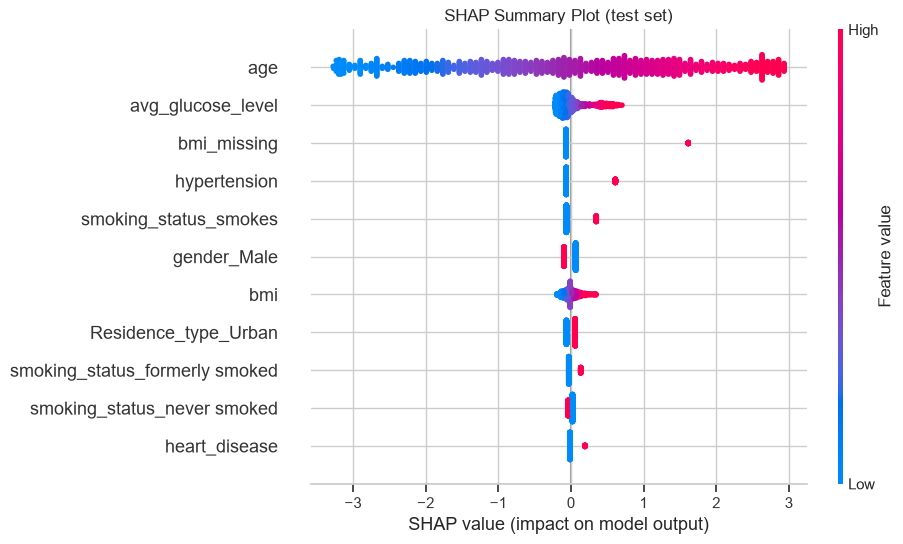

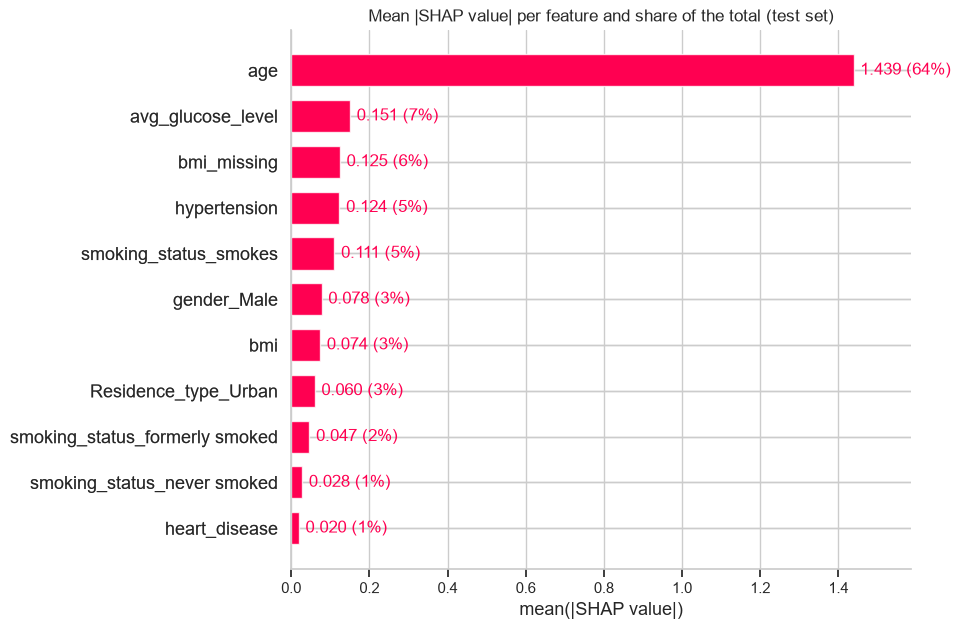

In [12]:
shap.plots.beeswarm(shap_values, max_display=len(feature_names), show=False)
plt.title("SHAP Summary Plot (test set)")
plt.show()

shap.plots.bar(shap_values, max_display=len(feature_names), show=False)
# Add each feature's share of the total mean |SHAP| to its bar label
ax = plt.gca()
mean_abs = pd.Series(np.abs(shap_values.values).mean(0), index=shap_values.feature_names)
share = mean_abs / mean_abs.sum() * 100
names = {round(t.get_position()[1]): t.get_text() for t in ax.get_yticklabels()}
for t in ax.texts:
    name = names[round(t.get_position()[1])]
    t.set_text(f"{mean_abs[name]:.3f} ({share[name]:.0f}%)")
plt.title("Mean |SHAP value| per feature and share of the total (test set)")
plt.show()

**Interpretation:** age alone accounts for 64% of the total mean |SHAP|, followed by glucose, missing BMI, hypertension and current smoking. In the beeswarm plot, red (high) values sit on the right for every feature, so higher values raise the risk; because the model is linear, each SHAP value is a straight line in the feature value.

### g) Explanation stability
Repeats the explanation with a different background (a random 500-patient sample of the training set, seed 1) and checks whether the top features and the main case's contribution signs change.

In [13]:
alt_background = X_train_t.sample(500, random_state=1)
alt_explainer = shap.LinearExplainer(model.named_steps["lr"], shap.maskers.Independent(alt_background, max_samples=500))
alt_values = alt_explainer(X_test_t)
alt_values.data = shap_values.data

def top5(sv):
    """Five features with the largest mean |SHAP value|."""
    return pd.Series(np.abs(sv.values).mean(0), index=sv.feature_names).nlargest(5).index.tolist()


top_full, top_alt = top5(shap_values), top5(alt_values)
print(f"Base value: {base:.3f} (full training set) vs {alt_explainer.expected_value:.3f} (500 sample)")
print("Top 5 (full):  ", top_full)
print("Top 5 (sample):", top_alt)
same_sign = np.sign(shap_values.values[main]) == np.sign(alt_values.values[main])
print(f"Main case: {same_sign.sum()} of {len(same_sign)} contributions keep their sign; changed:",
      [f for f, s in zip(feature_names, same_sign) if not s])

Base value: -1.323 (full training set) vs -1.295 (500 sample)
Top 5 (full):   ['age', 'avg_glucose_level', 'bmi_missing', 'hypertension', 'smoking_status_smokes']
Top 5 (sample): ['age', 'avg_glucose_level', 'bmi_missing', 'hypertension', 'smoking_status_smokes']
Main case: 11 of 11 contributions keep their sign; changed: []


**Interpretation:** the top 5 features are identical with the 500-patient background, and all 11 contribution signs for the main case are unchanged, so the explanation is stable with respect to the background.

### h) Subgroup performance
Stroke recall and precision by gender and age group on the test set. Positive counts are small, so these are indicative only.

In [ ]:
def subgroup_table(y_true, y_hat, groups):
    rows = []
    for name, g in groups.items():
        for level in sorted(g.unique()):
            m = (g == level).values
            yt, yp = y_true.values[m], y_hat[m]
            rows.append({"group": name, "level": level, "patients": m.sum(), "strokes": yt.sum(),
                         "recall": (yp[yt == 1] == 1).mean() if yt.sum() else np.nan,
                         "precision": yt[yp == 1].mean() if (yp == 1).sum() else np.nan})
    return pd.DataFrame(rows).round(3)

age_group = pd.cut(X_test["age"], [0, 60, 120], right=False, labels=["under 60", "60 and over"]).astype(str)
subgroup_table(y_test, y_pred, {"gender": X_test["gender"], "age": age_group})

,group,level,patients,strokes,recall,precision
0,gender,Female,597,29,0.828,0.148
1,gender,Male,425,21,0.762,0.136
2,age,60 and over,275,38,1.000,0.165
3,age,under 60,747,12,0.167,0.040


**Interpretation:** recall is similar for women (0.83) and men (0.76) but differs sharply by age: all 38 strokes in patients aged 60 and over are detected, but only 2 of 12 in patients under 60 (0.17).